# Explore here

Instalar librerias 

In [5]:
%pip install lifelines

     ---------------------------------------- 0.0/80.3 kB ? eta -:--:--
     -------------- ----------------------- 30.7/80.3 kB 660.6 kB/s eta 0:00:01
     -------------------------------------- 80.3/80.3 kB 897.7 kB/s eta 0:00:00
  Installing build dependencies: started
  Installing build dependencies: finished with status 'done'
  Getting requirements to build wheel: started
  Getting requirements to build wheel: finished with status 'done'
  Preparing metadata (pyproject.toml): started
  Preparing metadata (pyproject.toml): finished with status 'done'
  Using cached cycler-0.12.1-py3-none-any.whl.metadata (3.8 kB)
     ---------------------------------------- 0.0/142.6 kB ? eta -:--:--
     ----------------------------------- -- 133.1/142.6 kB 4.0 MB/s eta 0:00:01
     -------------------------------------- 142.6/142.6 kB 2.1 MB/s eta 0:00:00
   ---------------------------------------- 0.0/409.1 kB ? eta -:--:--
   --------------------------------- ------ 337.9/409.1 kB 7.1 MB/s et

  You can safely remove it manually.

[notice] A new release of pip is available: 24.0 -> 26.3
[notice] To update, run: C:\Users\veron\AppData\Local\Microsoft\WindowsApps\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\python.exe -m pip install --upgrade pip


In [6]:
import pandas as pd
from lifelines import KaplanMeierFitter, CoxPHFitter

## Evaluación práctica

Dos archivos proporcionados 
* product_test.csv (con el valor y fecha de desembolso de cada crédito)
* portfolio_test.csv (con el historial de días de mora a lo largo del tiempo).

Objetivo principal es estimar la probabilidad de supervivencia de un crédito en un momento t ; es decir, la probabilidad de que aún no haya caído en default (definido como una mora superior a 60 días).

Importar los archivos 

In [9]:
url_prod = "https://raw.githubusercontent.com/it-ces/Datasets/main/product_test.csv"
url_port = "https://raw.githubusercontent.com/it-ces/Datasets/main/portfolio_test.csv"

prod = pd.read_csv(url_prod)
port = pd.read_csv(url_port)

In [10]:
print("--- PRODUCT TEST ---")
print(prod.info())

--- PRODUCT TEST ---
<class 'pandas.DataFrame'>
RangeIndex: 890 entries, 0 to 889
Data columns (total 3 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   PRODUCT_ID     890 non-null    int64  
 1   TOTAL_VALUE    890 non-null    float64
 2   DELIVERY_DATE  890 non-null    str    
dtypes: float64(1), int64(1), str(1)
memory usage: 21.0 KB
None


In [11]:
print("--- PORTFOLIO TEST ---")
print(port.info())

--- PORTFOLIO TEST ---
<class 'pandas.DataFrame'>
RangeIndex: 23710 entries, 0 to 23709
Data columns (total 3 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   PRODUCT_ID      23710 non-null  int64  
 1   PORTFOLIO_DATE  23710 non-null  str    
 2   DAYS_OVER_DUE   23710 non-null  float64
dtypes: float64(1), int64(1), str(1)
memory usage: 555.8 KB
None


In [14]:
col_comun = list(set(prod.columns).intersection(set(port.columns)))
print(col_comun)

['PRODUCT_ID']


La columna en comun que tienen las dos tablas es Product ID 

In [18]:
tabla_consolidada = pd.merge(prod, port, how='inner', on=col_comun) 
print(tabla_consolidada.info())

<class 'pandas.DataFrame'>
RangeIndex: 23710 entries, 0 to 23709
Data columns (total 5 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   PRODUCT_ID      23710 non-null  int64  
 1   TOTAL_VALUE     23710 non-null  float64
 2   DELIVERY_DATE   23710 non-null  str    
 3   PORTFOLIO_DATE  23710 non-null  str    
 4   DAYS_OVER_DUE   23710 non-null  float64
dtypes: float64(2), int64(1), str(2)
memory usage: 926.3 KB
None


In [23]:
print(tabla_consolidada)

       PRODUCT_ID  TOTAL_VALUE             DELIVERY_DATE PORTFOLIO_DATE  \
0         1080038   468.438528  2023-11-13T06:32:50.000Z     2024-07-24   
1         1080038   468.438528  2023-11-13T06:32:50.000Z     2024-03-29   
2         1080038   468.438528  2023-11-13T06:32:50.000Z     2024-06-25   
3         1080038   468.438528  2023-11-13T06:32:50.000Z     2024-02-25   
4         1080038   468.438528  2023-11-13T06:32:50.000Z     2023-12-25   
...           ...          ...                       ...            ...   
23705     1023497  2097.684608  2023-09-21T17:54:05.000Z     2025-01-25   
23706     1023497  2097.684608  2023-09-21T17:54:05.000Z     2024-10-24   
23707     1023497  2097.684608  2023-09-21T17:54:05.000Z     2024-05-24   
23708     1023497  2097.684608  2023-09-21T17:54:05.000Z     2024-03-29   
23709     1023497  2097.684608  2023-09-21T17:54:05.000Z     2023-12-25   

       DAYS_OVER_DUE  
0                0.0  
1                0.0  
2                2.0  
3      

In [31]:
tabla_consolidada['es_default'] = (tabla_consolidada['DAYS_OVER_DUE'] > 60).astype(int)
print(tabla_consolidada[['DAYS_OVER_DUE', 'es_default']].describe())

       DAYS_OVER_DUE    es_default
count   23710.000000  23710.000000
mean       22.148418      0.074441
std        74.700135      0.262493
min         0.000000      0.000000
25%         0.000000      0.000000
50%         1.000000      0.000000
75%         6.000000      0.000000
max      1174.000000      1.000000


In [33]:
resumen_creditos = tabla_consolidada.groupby('PRODUCT_ID').agg(
    valor_credito=('TOTAL_VALUE', 'first'),
    mora_maxima=('DAYS_OVER_DUE', 'max'),
    mora_promedio=('DAYS_OVER_DUE', 'mean'),
    cortes_observados=('PORTFOLIO_DATE', 'count'),
    cayo_en_default=('es_default', 'max') # 1 si en algún corte superó 60 días, 0 si nunca lo hizo
).reset_index()
print(resumen_creditos)

     PRODUCT_ID  valor_credito  mora_maxima  mora_promedio  cortes_observados  \
0        483590    2239.564190         60.0       3.000000                 46   
1        483933     727.609500         32.0       4.739130                 46   
2        495772     466.573210         33.0       6.695652                 46   
3        501115    1538.930237          6.0       1.717391                 46   
4        519155    2123.307192       1174.0      57.630435                 46   
..          ...            ...          ...            ...                ...   
885     1285173    1556.070675        139.0      38.900000                 10   
886     1285196    1524.830723         83.0      24.200000                 10   
887     1285269    2482.852780          1.0       0.100000                 10   
888     1285288    2389.680823         58.0      18.000000                 10   
889     1285337    1732.324967          4.0       2.100000                 10   

     cayo_en_default  
0   

In [34]:
print(resumen_creditos.head(50))
print("\nTotal de créditos:", len(resumen_creditos))
print("Créditos que hicieron default (> 60 días):", resumen_creditos['cayo_en_default'].sum())
print("Créditos censurados (nunca hicieron default):", (resumen_creditos['cayo_en_default'] == 0).sum())



    PRODUCT_ID  valor_credito  mora_maxima  mora_promedio  cortes_observados  \
0       483590    2239.564190         60.0       3.000000                 46   
1       483933     727.609500         32.0       4.739130                 46   
2       495772     466.573210         33.0       6.695652                 46   
3       501115    1538.930237          6.0       1.717391                 46   
4       519155    2123.307192       1174.0      57.630435                 46   
5       519161    1400.303881         31.0       1.434783                 46   
6       524822    2301.833784         54.0      14.130435                 46   
7       525305     967.369716         21.0       0.913043                 46   
8       526535    3309.828215         25.0       2.086957                 46   
9       527112     800.384677         59.0       4.413043                 46   
10      527753    2298.666235        198.0      23.434783                 46   
11      555342    1773.195801         19

In [40]:
tabla_consolidada['DELIVERY_DATE'] = pd.to_datetime(tabla_consolidada['DELIVERY_DATE']).dt.date
tabla_consolidada['PORTFOLIO_DATE'] = pd.to_datetime(tabla_consolidada['PORTFOLIO_DATE']).dt.date




In [41]:
df_surv = (
    tabla_consolidada
    .sort_values(by=['PRODUCT_ID', 'es_default', 'PORTFOLIO_DATE'], ascending=[True, False, True])
    .drop_duplicates(subset='PRODUCT_ID', keep='first')
    .copy()
)


In [42]:
ultima_fecha = tabla_consolidada.groupby('PRODUCT_ID')['PORTFOLIO_DATE'].max()
df_surv.loc[df_surv['es_default'] == 0, 'PORTFOLIO_DATE'] = df_surv['PRODUCT_ID'].map(ultima_fecha)


In [43]:


df_surv['t_dias'] = (pd.to_datetime(df_surv['PORTFOLIO_DATE']) - pd.to_datetime(df_surv['DELIVERY_DATE'])).dt.days
df_surv['t_meses'] = df_surv['t_dias'] / 30.4375
df_surv = df_surv.rename(columns={'es_default': 'evento'})
df_surv = df_surv[df_surv['t_dias'] > 0]



In [44]:
print(df_surv[['PRODUCT_ID', 'TOTAL_VALUE', 't_dias', 't_meses', 'evento']].head(30))

       PRODUCT_ID  TOTAL_VALUE  t_dias    t_meses  evento
23075      483590  2239.564190     923  30.324435       0
22419      483933   727.609500     704  23.129363       0
17848      495772   466.573210     616  20.238193       0
2272       501115  1538.930237    1251  41.100616       0
8033       519155  2123.307192     930  30.554415       1
9702       519161  1400.303881    1000  32.854209       0
7868       524822  2301.833784    1000  32.854209       0
11507      525305   967.369716    1401  46.028747       0
20632      526535  3309.828215     708  23.260780       0
14466      527112   800.384677     329  10.809035       0
19493      527753  2298.666235     481  15.802875       1
13646      555342  1773.195801     652  21.420945       0
2589       579364  1555.462761     333  10.940452       0
17663      603848  2307.913585     743  24.410678       0
1616       606148  2298.775338     583  19.154004       0
9222       608714   244.289586     277   9.100616       1
13153      611

In [45]:
import matplotlib.pyplot as plt
from lifelines import KaplanMeierFitter

In [46]:
kmf = KaplanMeierFitter()
kmf.fit(durations=df_surv['t_meses'], event_observed=df_surv['evento'])

<lifelines.KaplanMeierFitter:"KM_estimate", fitted with 887 total observations, 678 right-censored observations>

In [53]:
tiempos_consulta = [1, 3, 6, 12, 24, 36, 48, 60, 72, 84, 96, 108, 120]
probabilidades_supervivencia = kmf.survival_function_at_times(tiempos_consulta)

print("Probabilidades de supervivencia en meses específicos:")
for t, p in probabilidades_supervivencia.items():
    print(f"Mes {t}: {p:.4f} ({p*100:.2f}% de probabilidad de seguir al día/sin default)")

Probabilidades de supervivencia en meses específicos:
Mes 1: 1.0000 (100.00% de probabilidad de seguir al día/sin default)
Mes 3: 0.9944 (99.44% de probabilidad de seguir al día/sin default)
Mes 6: 0.9312 (93.12% de probabilidad de seguir al día/sin default)
Mes 12: 0.8537 (85.37% de probabilidad de seguir al día/sin default)
Mes 24: 0.7577 (75.77% de probabilidad de seguir al día/sin default)
Mes 36: 0.7089 (70.89% de probabilidad de seguir al día/sin default)
Mes 48: 0.6818 (68.18% de probabilidad de seguir al día/sin default)
Mes 60: 0.6818 (68.18% de probabilidad de seguir al día/sin default)
Mes 72: 0.6818 (68.18% de probabilidad de seguir al día/sin default)
Mes 84: 0.6818 (68.18% de probabilidad de seguir al día/sin default)
Mes 96: 0.6818 (68.18% de probabilidad de seguir al día/sin default)
Mes 108: 0.6818 (68.18% de probabilidad de seguir al día/sin default)
Mes 120: 0.6818 (68.18% de probabilidad de seguir al día/sin default)


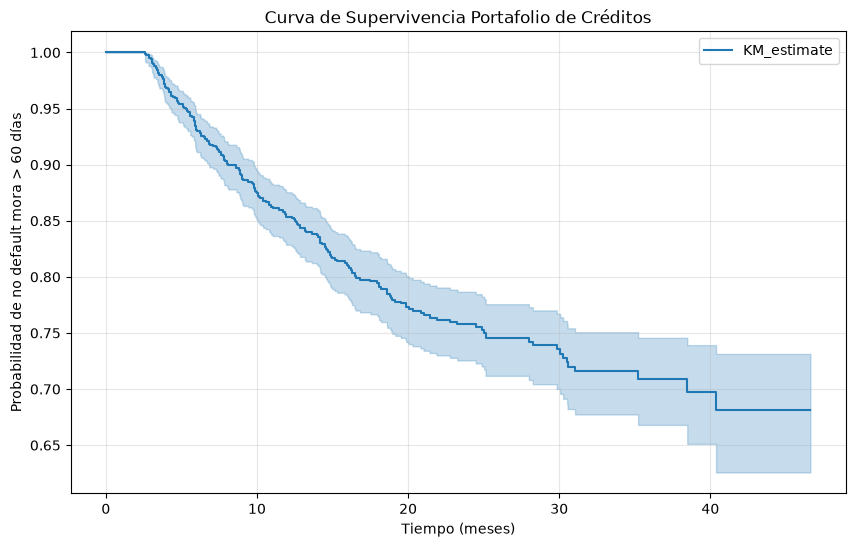

In [55]:
plt.figure(figsize=(10, 6))
kmf.plot_survival_function()
plt.title('Curva de Supervivencia Portafolio de Créditos')
plt.xlabel('Tiempo (meses)')
plt.ylabel('Probabilidad de no default mora > 60 días')
plt.grid(True,alpha=0.3)
plt.show()

In [57]:
cph = CoxPHFitter()
cph.fit(df_surv[['t_meses', 'evento', 'TOTAL_VALUE']], duration_col='t_meses', event_col='evento')
print(cph.summary)

                 coef  exp(coef)  se(coef)  coef lower 95%  coef upper 95%  \
covariate                                                                    
TOTAL_VALUE  0.000208   1.000208  0.000089        0.000034        0.000382   

             exp(coef) lower 95%  exp(coef) upper 95%  cmp to         z  \
covariate                                                                 
TOTAL_VALUE             1.000034             1.000382     0.0  2.348472   

                    p  -log2(p)  
covariate                        
TOTAL_VALUE  0.018851  5.729243  


.